# FloodScope: Mapping Water During Real Flood Events Using Satellite Radar Images

For this project, I use actual Sentinel-1 satellite measurements to predict which parts of an image contain water and compare a simple radar threshold with a random forest and a small convolutional neural network so I can see how each method performs on the reserved images. Afterwards, I train the same neural network with extra automatically labeled images before using the manual labels to check whether that additional training improves its predictions.

My main question is **whether imperfect automatic labels can help a model when the manually labeled dataset is small** so I use the published Sen1Floods11 splits and keep the Bolivia flood event outside training and validation to check how the methods perform on an event they have not learned from.

I explain the steps alongside the outputs below with the reusable functions in [`src`](src) and the saved measurements in [`results`](results).

## 1. What I need to predict

I predict an answer for each pixel through **image segmentation**, wherein the model produces another grid showing which locations contain water instead of assigning one answer to the whole image.

| Label | Meaning | How I use it |
| --- | --- | --- |
| `0` | Not water | Included in the loss and checking |
| `1` | Water | Included in the loss and checking |
| `-1` | No reliable reference answer | Ignored in the loss and checking |

The hand labels identify water which includes permanent rivers and lakes so the scores below measure **water detection during flood events**. I later subtract a permanent-water reference to illustrate a possible flood mask although that comparison does not provide separately verified flood-only answers.

## 2. Set up the experiment

I use two radar bands called **VV** and **VH** which measure different radar polarization responses rather than the red, green and blue values found in a photograph. Sentinel-1 can collect these measurements during the day or night and through cloud cover which makes radar useful for looking at flood events. [ESA mission description](https://www.esa.int/Applications/Observing_the_Earth/Copernicus/Sentinel-1/Introducing_the_Sentinel-1_mission)

I fixed the settings below before calculating either test score and used my CPU with four PyTorch threads and a small U-Net so I could run the experiment locally. These are the starting settings I tested rather than values that I have established to be the best possible ones.

The first download is approximately **865 MB** for this selection and later runs use the downloaded files and saved experiment. I can set `RETRAIN = True` to train again or read the saved outputs without rerunning the cells.

In [1]:
import os
import sys
import json
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'experiment.py').exists():
    ROOT = ROOT / 'floodscope'
if not (ROOT / 'src' / 'experiment.py').exists():
    raise FileNotFoundError('Open this notebook from floodscope or its parent folder.')
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
os.environ.setdefault('XDG_CACHE_HOME', str(ROOT / '.cache'))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.experiment import CONFIG, run_experiment, split_indices, scores, counts
from src.data import load_manifest, load_arrays, image_path, read_radar, read_label, normalize
from src.model import SmallUNet
from src.predict import Predictor
from src.report import training_figure, comparison_figure, examples_figure, permanent_water_figure, save_figure, WATER

RETRAIN = False
DOWNLOAD_IF_MISSING = True
torch.set_num_threads(CONFIG['threads'])

display(pd.DataFrame([
    ['Seed', CONFIG['seed'], 'Repeatable model initialization and sampling'],
    ['Prepared image size', '256 x 256', 'Same grid for all model comparisons'],
    ['Training crop', '128 x 128', 'Two randomly augmented crops per image each epoch'],
    ['Manual training epochs', CONFIG['epochs'], 'Maximum number of supervised passes'],
    ['Weak pretraining epochs', CONFIG['weak_pretrain_epochs'], 'Extra training on automatic labels'],
    ['Batch size', CONFIG['batch_size'], 'Crops per weight update'],
    ['Learning rate', CONFIG['learning_rate'], "AdamW's initial step size"],
    ['CPU threads', CONFIG['threads'], 'Local CPU calculations'],
], columns=['Setting', 'Value', 'What it controls']))

,Setting,Value,What it controls
0,Seed,42,Repeatable model initialization and sampling
1,Prepared image size,256 x 256,Same grid for all model comparisons
2,Training crop,128 x 128,Two randomly augmented crops per image each epoch
3,Manual training epochs,18,Maximum number of supervised passes
4,Weak pretraining epochs,4,Extra training on automatic labels
5,Batch size,16,Crops per weight update
6,Learning rate,0.001,AdamW's initial step size
7,CPU threads,4,Local CPU calculations


## 3. Read the actual satellite dataset

I use **Sen1Floods11 v1.1** from Cloud to Street which contains 446 manually labeled satellite image patches from real flood events. I also select up to eight additional weakly labeled images from each training event using seed 42 and use their automatic Sentinel-2 classifications as extra labels although these can contain mistakes. [Dataset documentation](https://github.com/cloudtostreet/Sen1Floods11/blob/master/docs/README.md)

I keep the published split files and save each downloaded file's source URL, object generation and checksums in `data/manifest.json` so I can check which files were used. The downloader also compares each file with the public storage checksum to verify the download.

In [2]:
if not (ROOT / 'data/manifest.json').exists():
    if not DOWNLOAD_IF_MISSING:
        raise FileNotFoundError('Set DOWNLOAD_IF_MISSING=True or run python -m src.prepare_data.')
    from src.prepare_data import prepare
    prepare()

manifest = load_manifest()
images, labels, rows = load_arrays(manifest)
metadata = pd.DataFrame(rows)
splits = split_indices(rows)
display(metadata.groupby(['split', 'event']).size().unstack(fill_value=0))
print('Radar array:', images.shape, '| label array:', labels.shape)
print('Source files:', len(manifest['files']))
print('Downloaded file size:', round(sum(item['bytes'] for item in manifest['files']) / 1e6, 1), 'MB')
print('Label values:', np.unique(labels))

event,Bolivia,Ghana,India,Mekong,Nigeria,Pakistan,Paraguay,Somalia,Spain,Sri-Lanka,USA
split,,,,,,,,,,,
bolivia,15,0,0,0,0,0,0,0,0,0,0
test,0,11,14,6,4,6,14,6,6,9,14
train,0,31,40,18,10,16,39,15,18,24,41
valid,0,11,14,6,4,6,14,5,6,9,14
weak_train,0,8,8,8,8,8,8,8,8,8,8


Radar array: (526, 2, 256, 256) | label array: (526, 256, 256)
Source files: 1502
Downloaded file size: 864.6 MB


Label values: [-1  0  1]


## 4. Look at the measurements before using a model

I first display an image from the training split alongside its manually checked water label so I can compare the measurements with the answers before training a model. The radar image is shown in grayscale and darker areas can be associated with water although other surfaces can also produce a weak response which is why I check a simple threshold as a baseline.

The blue region in the reference image means water and the gray region means there is no reliable reference label. I select a training image with mostly valid labels and a water fraction close to one quarter so both classes are easy to see without using any test answers to choose the example.

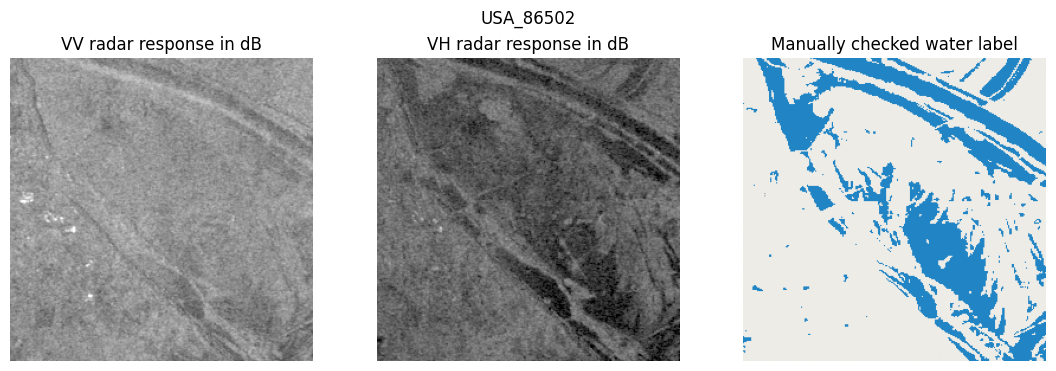

In [3]:
eligible_examples = [int(i) for i in splits['train'] if np.mean(labels[i] >= 0) > 0.9]
water_fraction = lambda i: np.mean(labels[i][labels[i] >= 0] == 1)
training_index = min(eligible_examples, key=lambda i: abs(water_fraction(i) - 0.25))
training_row = rows[training_index]
raw_radar, radar_valid, profile = read_radar(image_path(training_row))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), constrained_layout=True)
axes[0].imshow(raw_radar[0], cmap='gray', vmin=-35, vmax=5)
axes[0].set_title('VV radar response in dB')
axes[1].imshow(raw_radar[1], cmap='gray', vmin=-35, vmax=5)
axes[1].set_title('VH radar response in dB')
axes[2].imshow(np.ma.masked_where(labels[training_index] < 0, labels[training_index]), cmap=WATER, vmin=0, vmax=1)
axes[2].set_title('Manually checked water label')
for axis in axes:
    axis.set_axis_off()
fig.suptitle(training_row['chip'])
save_figure(fig, 'input_example.png')
display(fig)
plt.close(fig)

## 5. Split the data for training and checking

I keep the published **252 training images**, **89 validation images**, **90 ordinary test images** and **15 Bolivia images** wherein the training images update the weights while the validation images help me choose the checkpoint and decision threshold. I calculate the test results after fixing these choices so the checking images do not influence which model I select.

The ordinary test split checks new image patches from events that are also represented in training while Bolivia gives a stricter check because the whole event stays outside development. I also compare the map coordinates of the weakly labeled images and remove any that overlap a validation or test image so none of the checking images provides automatic training labels.

In [4]:
split_table = metadata.groupby('split').agg(images=('chip', 'size'), events=('event', 'nunique'))
display(split_table)
assert metadata.chip.is_unique
assert all(rows[i]['event'] != 'Bolivia' for name in ['train', 'valid', 'weak_train'] for i in splits[name])
assert set(splits['train']).isdisjoint(splits['valid'])
print('All chip IDs are unique and Bolivia is excluded from development.')

,images,events
split,,
bolivia,15,1
test,90,10
train,252,10
valid,89,10
weak_train,80,10


All chip IDs are unique and Bolivia is excluded from development.


## 6. Prepare the radar values

I reduce the original 512 by 512 images to **256 by 256** using average resampling for the radar values and nearest-neighbor resampling for the labels so all four approaches are checked on the same grid. This smaller grid removes some detail which means the scores should not be compared directly with published results calculated at the original resolution.

I clip the radar measurements to the fixed range of **−35 to 5 dB** and then scale that range to zero through one without calculating a mean or standard deviation from the test images. I store the prepared values at float16 precision and convert them back to float32 for calculations while keeping these same steps when I reload the trained model.

For training, I take two random 128 by 128 crops from each image per epoch and randomly rotate or mirror them while ignoring invalid reference pixels in both the training loss and the reported metrics.

In [5]:
training_labels = labels[splits['train']]
valid_training_pixels = training_labels >= 0
print('Input range:', float(images.min()), 'to', float(images.max()))
print('Valid labeled training pixels:', int(valid_training_pixels.sum()))
print('Water fraction among valid training pixels:', f'{np.mean(training_labels[valid_training_pixels] == 1):.2%}')

Input range: 0.0 to 1.0
Valid labeled training pixels: 14321570
Water fraction among valid training pixels: 9.51%


## 7. Build the comparison models

I compare the following approaches so I can check whether the neural network improves on the simpler methods.

| Method | What it learns or uses |
| --- | --- |
| VH threshold | One threshold chosen using validation water overlap |
| Random forest | VV, VH, their difference and local mean or variation features |
| U-Net with manual labels | Image patterns learned from the manually labeled training split |
| U-Net with weak pretraining | The same network, first trained on the selected automatic labels |

I train the random forest using a reproducible sample of up to 1,536 valid pixels per training image while the U-Net learns from image crops. The U-Net reduces the grid through three encoder stages and then increases it again through skip connections that combine earlier details with later features before returning one water score per pixel which I convert to a probability using sigmoid.

I use binary cross-entropy to check individual pixel probabilities together with Dice loss to consider the overlap between predicted and labeled water while ignoring `-1` labels in both parts. The architecture and loss are in [`src/model.py`](src/model.py) and the training loop is in [`src/experiment.py`](src/experiment.py).

In [6]:
architecture = SmallUNet(width=CONFIG['unet_width'])
print(architecture)
print('Trainable parameters:', sum(parameter.numel() for parameter in architecture.parameters()))
with torch.inference_mode():
    print('Example output shape:', tuple(architecture(torch.from_numpy(images[splits['train'][:1]])).shape))

SmallUNet(
  (encoder1): ConvBlock(
    (0): Conv2d(2, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): GroupNorm(4, 8, eps=1e-05, affine=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): GroupNorm(4, 8, eps=1e-05, affine=True)
    (5): ReLU(inplace=True)
  )
  (encoder2): ConvBlock(
    (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): GroupNorm(4, 16, eps=1e-05, affine=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): GroupNorm(4, 16, eps=1e-05, affine=True)
    (5): ReLU(inplace=True)
  )
  (encoder3): ConvBlock(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): GroupNorm(4, 32, eps=1e-05, affine=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
 

## 8. Train and choose the checkpoints

For each supervised epoch, I shuffle the training crops and compare their predicted water scores with the labels before AdamW updates the weights. Afterwards, I check the full validation images without changing the weights and keep the checkpoint and threshold with the highest pooled validation water intersection-over-union which I refer to as **IoU**.

`IoU = correctly predicted water / (correctly predicted water + false water alarms + missed water)`

A value of one means perfect overlap and I also use validation IoU to select the final method so the test scores do not determine which model is exported as the selected one. Both U-Nets receive the same maximum number of manual-label epochs although the weak-pretraining model gets four extra epochs on the automatic labels which means it also uses more training time.

The following cell runs the experiment if results are missing or loads the saved experiment when `RETRAIN = False` so I can check the results without training again.

In [7]:
summary = run_experiment(force=RETRAIN)
audit = summary['data_audit']
print('Actual split sizes after the spatial audit:', audit['splits'])
print('Overlapping weak images removed:', len(audit['overlapping_weak_chips_removed']))
print('Selected method:', summary['selection']['selected_model'])
print('Original experiment runtime:', round(summary['elapsed_seconds'] / 60, 2), 'minutes')
display(pd.DataFrame(summary['versions'].items(), columns=['Package', 'Version']))

Using the saved completed experiment. Set force=True to retrain.
Actual split sizes after the spatial audit: {'train': 252, 'valid': 89, 'test': 90, 'bolivia': 15, 'weak_train': 80}
Overlapping weak images removed: 0
Selected method: unet_manual
Original experiment runtime: 18.08 minutes


,Package,Version
0,python,3.12.5
1,torch,2.7.0
2,numpy,1.26.4
3,pandas,2.2.1
4,scipy,1.13.1
5,scikit_learn,1.7.2


## 9. Check the validation results and training curves

I use the validation results to select from the settings I tested and keep an earlier checkpoint if later updates reduce validation overlap. The table below shows the selected settings while the graph shows how the loss and validation IoU changed during training with the manual labels.

,model,validation_water_iou,selected_threshold
2,unet_manual,0.6001,0.4
3,unet_weak_then_manual,0.5997,0.2
1,random_forest,0.5986,0.7
0,vh_threshold,0.5194,-23.0


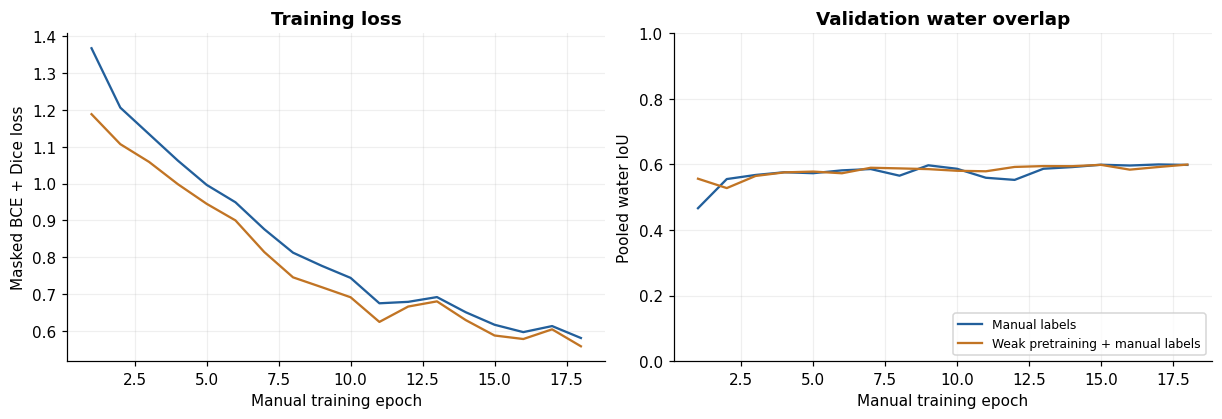

In [8]:
validation = pd.DataFrame([
    {'model': name, 'validation_water_iou': value,
     'selected_threshold': summary['selection']['thresholds'][name]}
    for name, value in summary['selection']['validation_water_iou'].items()
]).sort_values('validation_water_iou', ascending=False)
display(validation.round(4))
fig = training_figure()
display(fig)
plt.close(fig)

## 10. Check the reserved images

I now compare the selected checkpoints on the ordinary test split and the unseen Bolivia event using **precision** to measure how often a predicted water pixel is correct and **recall** to measure how much of the labeled water the model finds. **F1** balances these two measurements while IoU is my main comparison because overall accuracy can appear high when most pixels are land.

I calculate the pooled metrics across all valid pixels in each split and save each chip's confusion counts and IoU so I can see how performance changes between images. The mean chip IoU excludes chips with neither labeled nor predicted water because their IoU denominator is zero while pixels with `-1` labels contribute to none of the counts.

,split,model,chips,water_iou,precision,recall,f1,mean_chip_water_iou
4,test,vh_threshold,90,0.5658,0.7447,0.7019,0.7227,0.3067
5,test,random_forest,90,0.6283,0.8080,0.7386,0.7717,0.3484
6,test,unet_manual,90,0.6348,0.7799,0.7733,0.7766,0.3559
7,test,unet_weak_then_manual,90,0.6343,0.7734,0.7792,0.7763,0.3570
8,bolivia,vh_threshold,15,0.6139,0.8725,0.6744,0.7608,0.3793
9,bolivia,random_forest,15,0.5970,0.8936,0.6426,0.7476,0.3981
10,bolivia,unet_manual,15,0.6294,0.8547,0.7048,0.7726,0.4123
11,bolivia,unet_weak_then_manual,15,0.6240,0.8594,0.6949,0.7684,0.4088


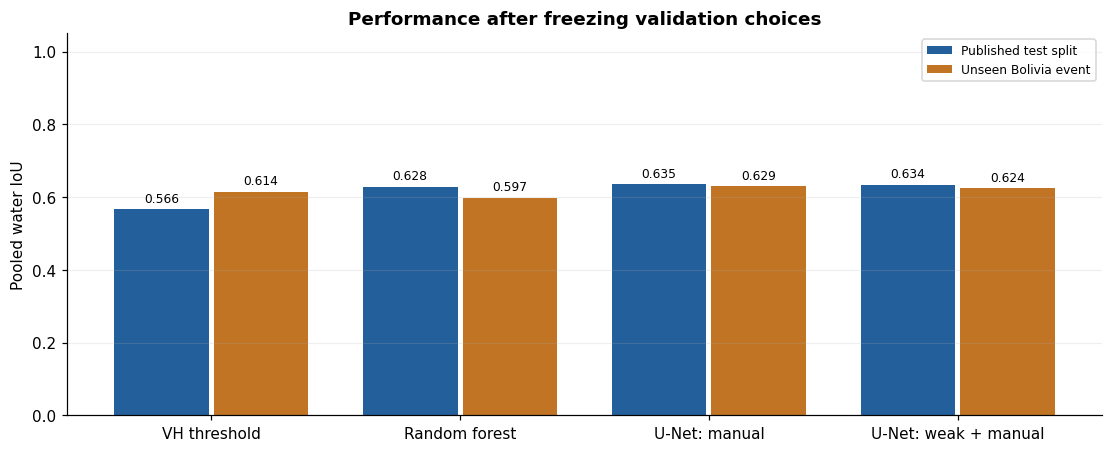

In [9]:
metrics = pd.read_csv(ROOT / 'results/metrics.csv')
checking = metrics[metrics.split.isin(['test', 'bolivia'])]
display(checking[['split', 'model', 'chips', 'water_iou', 'precision', 'recall', 'f1', 'mean_chip_water_iou']].round(4))
fig = comparison_figure()
display(fig)
plt.close(fig)

## 11. Look at where the selected model makes mistakes

I use the model selected on validation to show the Bolivia images with the lowest, middle and highest chip IoU so I can compare where its predictions work well and where they fail. I choose these examples after scoring to show different levels of performance rather than treating three images as representative of the whole event.

Blue shows correctly predicted water while amber shows water predicted on labeled land and red shows labeled water that the model missed. Gray pixels do not have a reliable reference answer and I save the complete per-chip measurements in `results/per_chip_metrics.csv` so the other images can be checked as well.

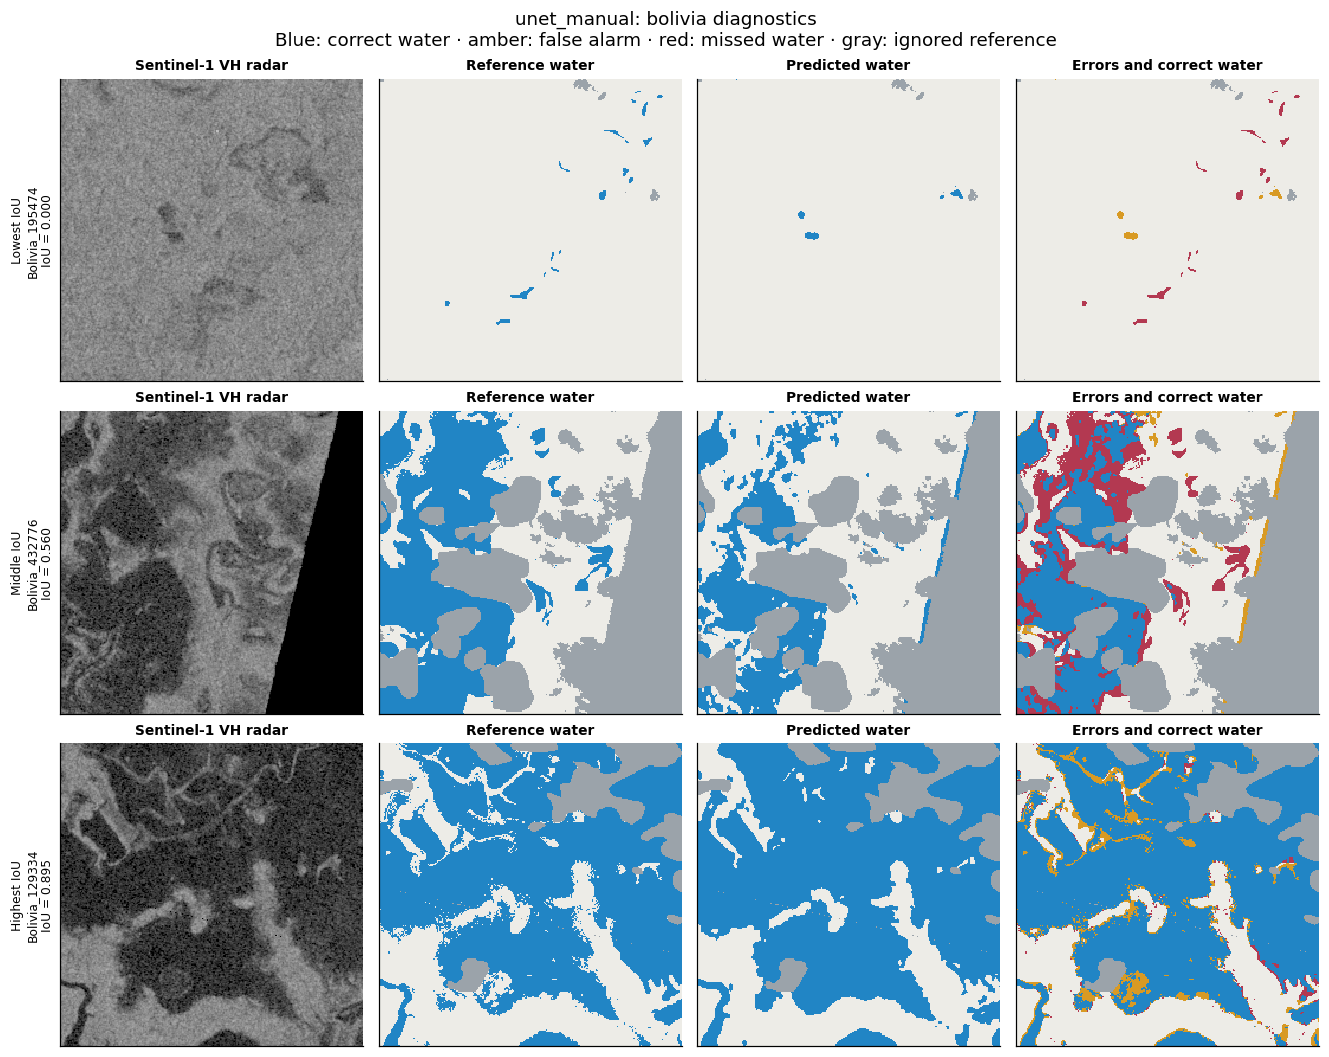

In [10]:
fig = examples_figure()
display(fig)
plt.close(fig)

## 12. Did the automatic labels help?

I compare the manual-only U-Net with the U-Net that first saw weak labels while keeping their architecture, manual training budget and split definitions the same. I report both checking groups because an improvement in one location would not establish an improvement everywhere.

This is one seeded experiment with a limited sample of weak images so I use it to describe what happened under this recipe without claiming that weak supervision is always helpful. I would need to repeat the comparison with several seeds and larger weak-label samples to check whether the result is consistent.

In [11]:
weak_comparison = checking[checking.model.str.startswith('unet')].pivot(index='split', columns='model', values='water_iou')
weak_comparison['change_in_iou_points'] = 100 * (weak_comparison['unet_weak_then_manual'] - weak_comparison['unet_manual'])
display(weak_comparison.round(4))
for split, row in weak_comparison.iterrows():
    change = row['change_in_iou_points']
    direction = 'increased' if change > 0 else 'decreased' if change < 0 else 'did not change'
    print(f'On {split}, weak pretraining {direction} water IoU by {abs(change):.2f} percentage points.')

model,unet_manual,unet_weak_then_manual,change_in_iou_points
split,,,
bolivia,0.6294,0.6240,-0.5441
test,0.6348,0.6343,-0.0440


On bolivia, weak pretraining decreased water IoU by 0.54 percentage points.
On test, weak pretraining decreased water IoU by 0.04 percentage points.


## 13. Reload the selected model and make a new prediction

I reload the exported model from disk and compare its predictions on reserved Bolivia images with the recorded masks to check that the saved files reproduce the same result. I keep this model tied to its original training and validation experiment without retraining it on the checking images after reporting the scores.

I also export a GeoTIFF to preserve the image location and map transform using the Bolivia chip with the largest predicted water fraction so the water mask is easy to inspect. The exported grid has 256 by 256 pixels with `0` for not water, `1` for water and `255` where the radar input is invalid. I exclude unknown reference labels from scoring but still allow predictions wherever the radar measurements are valid.

In [12]:
predictor = Predictor()
bolivia_indices = splits['bolivia'][:8]
reloaded_predictions = predictor.predict(images[bolivia_indices])
with np.load(ROOT / f'results/predictions/{predictor.name}_bolivia.npz') as saved:
    recorded = saved['predictions'][:len(bolivia_indices)].astype(bool)
    example_position = int(np.argmax(saved['predictions'].mean(axis=(1, 2))))
assert np.array_equal(reloaded_predictions, recorded)
example_index = int(splits['bolivia'][example_position])
example_row = rows[example_index]
output_path = predictor.predict_file(image_path(example_row), ROOT / 'results/example_water_prediction.tif')
print('Reloaded model:', predictor.name)
print('Saved-model predictions match the recorded masks.')
print('Exported:', output_path.relative_to(ROOT))

Reloaded model: unet_manual
Saved-model predictions match the recorded masks.
Exported: results/example_water_prediction.tif


## 14. Illustrate a possible flood mask

To look at possible flooded areas, I compare the current prediction with the dataset's JRC permanent-water reference and mark predicted water outside that reference as a **candidate flooded area**. This comparison can also include seasonal water, reference errors or model mistakes so I keep it separate from the verified water-segmentation scores.

I use this figure to illustrate the comparison on a real geographic image although I have not measured flood-only accuracy or tested a Philippine event in this version.

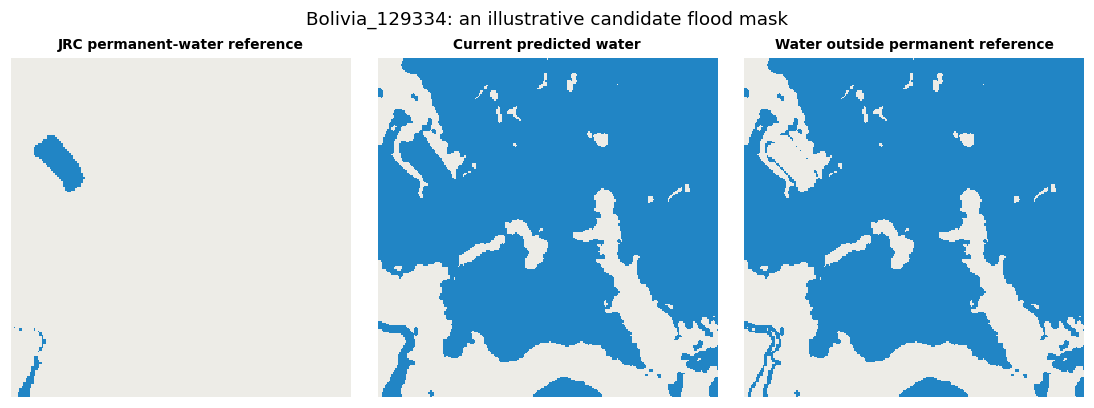

In [13]:
example_prediction = predictor.predict(images[example_index])
fig = permanent_water_figure(example_row['chip'], example_prediction)
display(fig)
plt.close(fig)

## 15. What I can conclude from this experiment

I use the measured values below to describe how the selected method performed after choosing it through validation so I can compare its predictions on new patches from familiar events with those from an event it has not learned from.

In [14]:
selected = predictor.name
selected_results = checking[checking.model == selected].set_index('split')
ordinary = selected_results.loc['test']
unseen = selected_results.loc['bolivia']
display(Markdown(
    f'I compared four approaches using real satellite observations and used validation water IoU to select **{selected}** '
    f'which achieved **{ordinary.water_iou:.4f} water IoU** on the {int(ordinary.chips)} ordinary test images '
    f'and **{unseen.water_iou:.4f} water IoU** on the {int(unseen.chips)} images from the unseen Bolivia event. '
    f'These measurements apply to the prepared 256 by 256 grid and the reference pixels with known answers '
    'while the saved examples, automatic-label comparison and model files allow the results to be checked alongside a georeferenced prediction. '
    'I would need to repeat the experiment across more unseen events and seeds and obtain independent flood-only labels '
    'before making broader claims about flood mapping.'
))

I compared four approaches using real satellite observations and used validation water IoU to select **unet_manual** which achieved **0.6348 water IoU** on the 90 ordinary test images and **0.6294 water IoU** on the 15 images from the unseen Bolivia event. These measurements apply to the prepared 256 by 256 grid and the reference pixels with known answers while the saved examples, automatic-label comparison and model files allow the results to be checked alongside a georeferenced prediction. I would need to repeat the experiment across more unseen events and seeds and obtain independent flood-only labels before making broader claims about flood mapping.

## Sources and saved files

- Bonafilia, D., Tellman, B., Anderson, T., and Issenberg, E. (2020). **Sen1Floods11: A Georeferenced Dataset to Train and Test Deep Learning Flood Algorithms for Sentinel-1.** IEEE/CVF CVPR Workshops. [Paper](https://www.grss-ieee.org/wp-content/uploads/earthvision2020/july_stuff/webpage/papers/Bonafilia_Sen1Floods11_A_Georeferenced_Dataset_to_Train_and_Test_Deep_Learning_CVPRW_2020_paper.pdf), [dataset and access instructions](https://github.com/cloudtostreet/Sen1Floods11).
- [Sen1Floods11 file and label documentation](https://github.com/cloudtostreet/Sen1Floods11/blob/master/docs/README.md).
- [ESA: Sentinel-1 mission](https://www.esa.int/Applications/Observing_the_Earth/Copernicus/Sentinel-1/Introducing_the_Sentinel-1_mission).
- [U-Net original paper](https://arxiv.org/abs/1505.04597). This experiment uses a much smaller adaptation with two radar inputs and group normalization.

I save the selected method in `models/selection.json` alongside both trained U-Nets and the forest in `models/` so the comparisons can be repeated from the exported files. The aggregate scores are in `results/metrics.csv` with individual image scores in `results/per_chip_metrics.csv` and the fixed settings in `results/config.json`. The raw dataset and local environment are excluded by `.gitignore` so they can be downloaded separately when sharing the repository.